# Overcoming Template Mega Clusters and Pooling Cancellation in Unsupervised Incident Triage

**Authors:** Zakaria Sherif ([LinkedIn](https://www.linkedin.com/in/zakaria-sherif/)), Nicholas Cosereanu ([LinkedIn](https://www.linkedin.com/in/nick-cosereanu-69b968325/)), Wyatt Barker ([LinkedIn](https://www.linkedin.com/in/james-wyatt-barker/))  
**Status:** Preprint — College of Computing and Software Engineering (CCSE), Kennesaw State University  
**Corpora:** Open-Source SWE GitHub Stream (`lewtun/github-issues`, $N=881$) & Enterprise IT Service Desk Benchmark ($N=1,380$)

---

### Executive Summary
Standard unsupervised topic models fall into two systematic traps when applied to technical incident streams:
1. **The Template & Mega Cluster Trap:** Automated sliding-window coherence ($C_v$) rewards models that group recurring submission boilerplate (`hello team`, `error message`, `dataset`), while default HDBSCAN Excess of Mass (EOM) merges distinct software failure modes into a single 298-ticket mega cluster (`R1`).
2. **The Static Window Trap:** Coarse two-period comparisons suffer from **pooling cancellation** (an opposing dip and surge cancel out once pooled) and cannot separate an active chronic bug plateau from a completed internal coding sprint.

This interactive notebook reproduces all three stages of our framework (**Discover → Track → Validate**) end-to-end using the project's exact corpora, embeddings, statistical tests, and withheld operational metadata.


In [1]:
# 1. Environment Setup & Load Both Benchmark Corpora
import json
import os
import re
import subprocess
from collections import Counter
from pathlib import Path

import hdbscan
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import adjusted_rand_score, silhouette_score
import umap

from temporal_tracking import (
    TemporalConfig,
    analyze_temporal_topics,
    focus_topic_quarter,
)
from trajectory_comparisons import compare_quarter_trajectories

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "figure.dpi": 130,
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
})

ROOT = Path(".").resolve()
df_gh = pd.read_csv(ROOT / "github_issues_180d.csv")
df_gh["datetime"] = pd.to_datetime(df_gh["datetime"], utc=True, errors="coerce", format="mixed").dt.tz_localize(None)
df_gh["quarter_period"] = df_gh["datetime"].dt.to_period("Q").astype(str)

df_it = pd.read_csv(ROOT / "it_incident_tickets.csv")
df_it["datetime"] = pd.to_datetime(df_it["date"], errors="coerce")
df_it["year"] = df_it["datetime"].dt.year
df_it["month"] = df_it["datetime"].dt.to_period("M").astype(str)

npz = np.load(ROOT / "paper_q2_results" / "joint_embeddings.npz")
gh_emb_384 = npz["embeddings"]
gh_umap_5d = npz["umap_5d"]
r_assign = pd.read_csv(ROOT / "paper_q2_results" / "topic_assignments.csv")["hdbscan_cluster"].to_numpy()
df_gh["r_cluster"] = r_assign

print(f"GitHub SWE Corpus : {len(df_gh):,} records | Q1={int((df_gh['quarter_period']=='2021Q1').sum())}, Q2={int((df_gh['quarter_period']=='2021Q2').sum())}")
print(f"Enterprise IT     : {len(df_it):,} records | Q1 2021={int((df_it['year']==2021).sum())}, 2024 slice={int((df_it['year']==2024).sum())}")
print(f"Unassigned IT     : {int((df_it['assignment_group_consolidated']=='Unassigned').sum())} orphaned tickets ({(df_it['assignment_group_consolidated']=='Unassigned').mean()*100:.1f}%)")
print(f"Cached Embeddings : SBERT 384D {gh_emb_384.shape} -> UMAP 5D {gh_umap_5d.shape}")


GitHub SWE Corpus : 881 records | Q1=478, Q2=403
Enterprise IT     : 1,380 records | Q1 2021=1338, 2024 slice=42
Unassigned IT     : 314 orphaned tickets (22.8%)
Cached Embeddings : SBERT 384D (881, 384) -> UMAP 5D (881, 5)


---
## 2. Trap 1: The Template Coherence Mirage & Breaking the 298-Ticket Mega Cluster

### 2A. Why $C_v$ Word Coherence Is a Mirage on Templated Ticket Streams
Because submission boilerplate appears across nearly every 110-token sliding window, classical bag-of-words baselines (LDA, TF-IDF+$K$-Means) earn artificially high $C_v$ coherence while collapsing geometrically (`Sil.5D <= 0.058`) and mixing unrelated tickets. Stripping domain boilerplate and clustering on a 5D UMAP manifold with **Bounded EOM** maximizes geometric separation and operational purity.


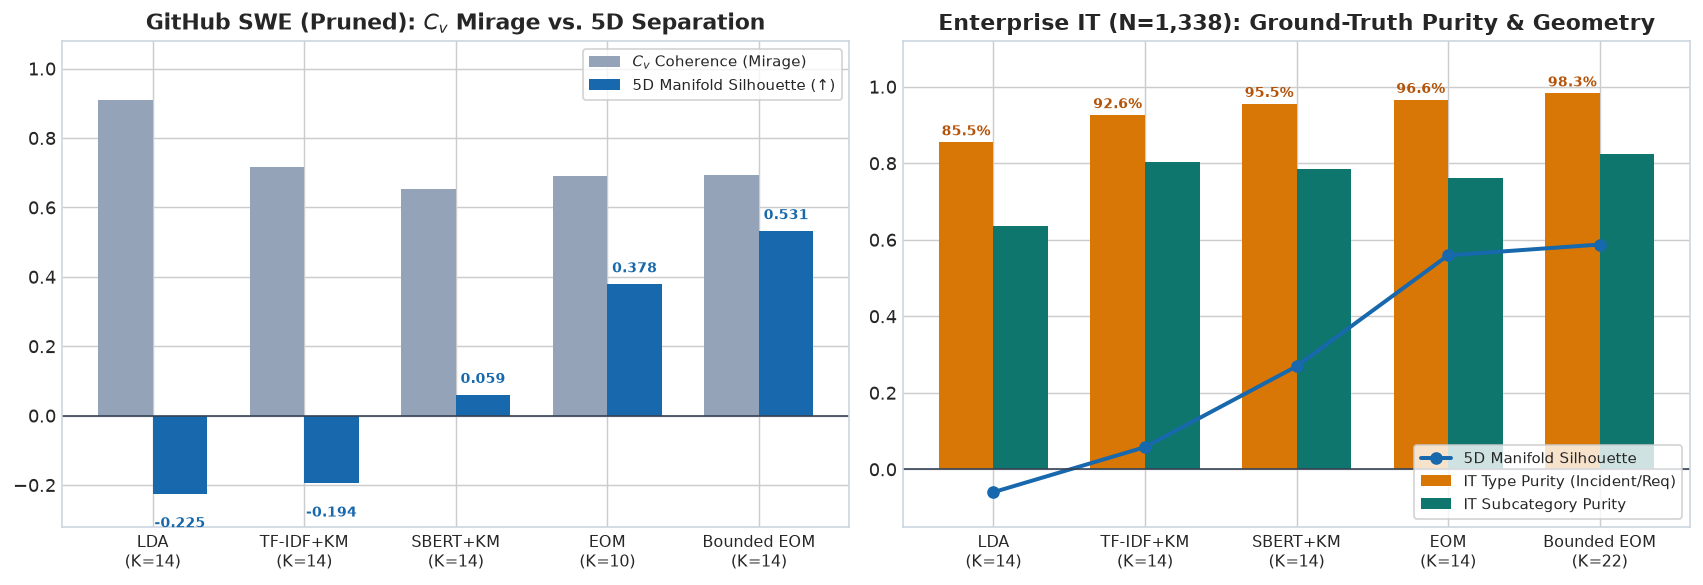

,Model,K,Noise_Ratio,Cv_Coherence,Topic_Diversity,Sil_UMAP_5D,Purity_Type,Purity_Subcategory,Purity_Support_Team
0,Classical LDA (K=14),14,0.0000,0.9052,0.8357,-0.0598,0.8550,0.6360,0.5977
1,Sparse TF-IDF + K-Means (K=14),14,0.0000,0.9367,0.9000,0.0580,0.9260,0.8042,0.7207
2,Dense SBERT + K-Means (K=14),14,0.0000,0.8738,0.9357,0.2692,0.9552,0.7862,0.7227
3,"Proposed SBERT+UMAP+HDBSCAN (EOM, K=14)",14,0.1487,0.8400,0.9786,0.5594,0.9658,0.7603,0.6918
4,"Proposed SBERT+UMAP+HDBSCAN (Bounded-EOM, K=22)",22,0.3445,0.8966,0.9136,0.5875,0.9829,0.8233,0.7133


In [2]:
# Compare Tri-Model Benchmarks across GitHub SWE (Exp 1) and Enterprise IT (Exp 7)
exp1 = pd.read_csv(ROOT / "final_experiments" / "exp1_trimodel_ablation.csv")
exp7 = pd.read_csv(ROOT / "final_experiments" / "exp7_it_trimodel_benchmark.csv")

swe_pruned = exp1[exp1["Preprocessing"] == "Domain-Pruned"].copy()
swe_pruned = swe_pruned[swe_pruned["K"] >= 10].iloc[3:]  # K=14 baselines + EOM (10) + BEOM (14)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))

# Panel A: GitHub SWE Coherence Mirage vs 5D Manifold Silhouette
models_swe = ["LDA\n(K=14)", "TF-IDF+KM\n(K=14)", "SBERT+KM\n(K=14)", "EOM\n(K=10)", "Bounded EOM\n(K=14)"]
cv_swe = swe_pruned["Cv_Coherence"].to_numpy()
sil_swe = swe_pruned["Sil_UMAP_5D_Clean"].to_numpy()
x = np.arange(len(models_swe))
w = 0.36
b1 = axes[0].bar(x - w/2, cv_swe, width=w, color="#94a3b8", label="$C_v$ Coherence (Mirage)")
b2 = axes[0].bar(x + w/2, sil_swe, width=w, color="#1768ac", label="5D Manifold Silhouette (↑)")
axes[0].axhline(0, color="#334155", lw=0.9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_swe, fontsize=9)
axes[0].set_ylim(-0.32, 1.08)
axes[0].set_title("GitHub SWE (Pruned): $C_v$ Mirage vs. 5D Separation", fontweight="bold")
axes[0].legend(frameon=True, fontsize=8.5, loc="upper right")
for bar in b2:
    val = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, val + (0.025 if val >= 0 else -0.065),
                 f"{val:.3f}", ha="center", va="bottom" if val >= 0 else "top", fontsize=8, fontweight="bold", color="#1768ac")

# Panel B: Enterprise IT Purity & 5D Silhouette
models_it = ["LDA\n(K=14)", "TF-IDF+KM\n(K=14)", "SBERT+KM\n(K=14)", "EOM\n(K=14)", "Bounded EOM\n(K=22)"]
x2 = np.arange(len(models_it))
axes[1].bar(x2 - w/2, exp7["Purity_Type"], width=w, color="#d97706", label="IT Type Purity (Incident/Req)")
axes[1].bar(x2 + w/2, exp7["Purity_Subcategory"], width=w, color="#0f766e", label="IT Subcategory Purity")
axes[1].plot(x2, exp7["Sil_UMAP_5D"], color="#1768ac", marker="o", lw=2.2, label="5D Manifold Silhouette")
axes[1].axhline(0, color="#334155", lw=0.9)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(models_it, fontsize=9)
axes[1].set_ylim(-0.15, 1.12)
axes[1].set_title("Enterprise IT (N=1,338): Ground-Truth Purity & Geometry", fontweight="bold")
axes[1].legend(frameon=True, fontsize=8.5, loc="lower right")
for i, v in enumerate(exp7["Purity_Type"]):
    axes[1].text(x2[i] - w/2, v + 0.018, f"{v*100:.1f}%", ha="center", fontsize=7.8, fontweight="bold", color="#b45309")

plt.tight_layout()
plt.show()

display(exp7[["Model", "K", "Noise_Ratio", "Cv_Coherence", "Topic_Diversity", "Sil_UMAP_5D", "Purity_Type", "Purity_Subcategory", "Purity_Support_Team"]].round(4))


Unbounded EOM R1 size        : 298 tickets (46.5% of assigned records)
ARI outside R1 (EOM vs BEOM) : 1.0000 (9 sibling clusters untouched)
R1 decomposition into Bounded EOM C-clusters: {-1: 96, 2: 31, 3: 23, 5: 92, 7: 35, 8: 21}


,Bounded_ID,Parent_EOM,Tickets,Top_Pruned_cTFIDF_Keywords
0,C0,R0,29,"wikimedia, duplicatedkeyserror, timit_asr, duplicate, wikidump author"
1,C1,R2,20,"rename_column, formatted, add_item, foo, comparison"
2,C2,R1,31,"tensor, jax, array, conversion, np"
3,C3,R1,23,"programdata anaconda3, envs env, programdata, requirement, requirement satisfied"
4,C4,R3,20,"git src, prepare_for_task, textclassification, git, datasetinfo"
5,C5,R1,92,"pickle, mnt appl, appl software, software gcccore, gcccore lib"
6,C6,R4,29,"char_error_rate, refs, cer, preds, compute predictions"
7,C7,R1,35,"int64, value dtype, dtype, int64 id, dtype int64"
8,C8,R1,21,"value dtype, _libs, input_ids label, question1 question2, question2"
9,C9,R5,31,"minor, deprecated, typo, bertscore, cer"


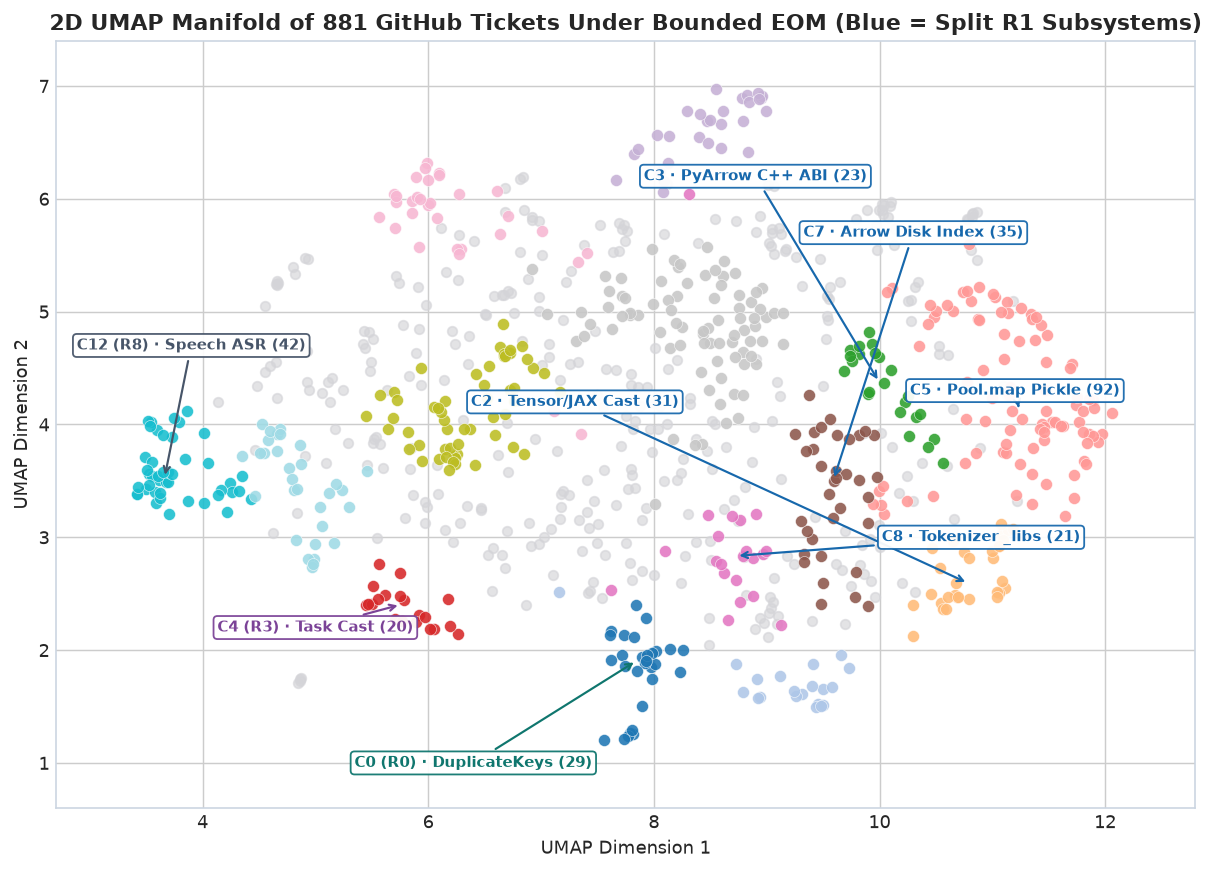

In [3]:
# 2B. Live Bounded EOM Decomposition of the 298-Ticket R1 Mega Cluster
c_labels = hdbscan.HDBSCAN(
    min_cluster_size=16,
    min_samples=5,
    max_cluster_size=120,
    metric="euclidean",
    cluster_selection_method="eom",
).fit_predict(gh_umap_5d)
df_gh["c_cluster"] = c_labels

# Verify R1 split vs ARI=1.000 outside R1
r1_mask = df_gh["r_cluster"] == 1
r1_split = df_gh.loc[r1_mask, "c_cluster"].value_counts().sort_index()
non_r1_ari = adjusted_rand_score(df_gh.loc[~r1_mask, "r_cluster"], df_gh.loc[~r1_mask, "c_cluster"])
print(f"Unbounded EOM R1 size        : {int(r1_mask.sum())} tickets (46.5% of assigned records)")
print(f"ARI outside R1 (EOM vs BEOM) : {non_r1_ari:.4f} (9 sibling clusters untouched)")
print("R1 decomposition into Bounded EOM C-clusters:", r1_split.to_dict())

# Compute Domain-Pruned c-TF-IDF keywords for C0..C13
DOMAIN_STOPS = {
    "dataset", "datasets", "data", "https", "http", "github", "com", "org",
    "add", "added", "adding", "issue", "issues", "fix", "fixed", "pr", "pull",
    "request", "test", "tests", "using", "use", "used", "file", "files",
    "python", "code", "run", "running", "line", "self", "error", "fails", "failed",
    "like", "need", "want", "does", "way", "make", "just", "new", "support", "version",
}
ALL_STOPS = sorted(ENGLISH_STOP_WORDS.union(DOMAIN_STOPS))
c_ids = sorted(int(c) for c in set(c_labels) if c != -1)
cluster_docs = [" ".join(df_gh.loc[df_gh["c_cluster"] == c, "text"].fillna("")) for c in c_ids]
cv = CountVectorizer(stop_words=ALL_STOPS, ngram_range=(1, 2), max_features=2500)
X = cv.fit_transform(cluster_docs).toarray().astype(np.float64)
vocab = np.array(cv.get_feature_names_out())
tf = X / np.maximum(X.sum(axis=1, keepdims=True), 1.0)
cf = (X > 0).sum(axis=0)
idf = np.log((len(c_ids) + 1.0) / (cf + 1.0)) + 1.0
weights = tf * idf
weights[:, cf > max(1, int(len(c_ids) * 0.35))] = 0.0

rows = []
for idx, cid in enumerate(c_ids):
    ranked = [i for i in np.argsort(weights[idx])[::-1] if weights[idx, i] > 0][:5]
    parent_r = df_gh.loc[df_gh["c_cluster"] == cid, "r_cluster"].mode().iloc[0]
    rows.append({
        "Bounded_ID": f"C{cid}",
        "Parent_EOM": f"R{parent_r}",
        "Tickets": int((c_labels == cid).sum()),
        "Top_Pruned_cTFIDF_Keywords": ", ".join(vocab[ranked]),
    })
display(pd.DataFrame(rows))

# 2D UMAP Spatial Plot with R1 Subsystem Callouts
coords_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.12, metric="cosine", random_state=42, n_jobs=1).fit_transform(gh_emb_384)
fig, ax = plt.subplots(figsize=(10.5, 6.8))
noise = c_labels == -1
ax.scatter(coords_2d[noise, 0], coords_2d[noise, 1], s=28, color="#d4d4d8", alpha=0.65, label=f"Noise ({noise.mean()*100:.1f}%)")
cmap = plt.get_cmap("tab20")
for cid in c_ids:
    pts = coords_2d[c_labels == cid]
    ax.scatter(pts[:, 0], pts[:, 1], s=44, color=cmap(cid / 13), alpha=0.88, edgecolors="white", linewidths=0.3)

callouts = [
    (5, "C5 · Pool.map Pickle (92)", (11.2, 4.3), "#1768ac"),
    (7, "C7 · Arrow Disk Index (35)", (10.3, 5.7), "#1768ac"),
    (2, "C2 · Tensor/JAX Cast (31)", (7.3, 4.2), "#1768ac"),
    (3, "C3 · PyArrow C++ ABI (23)", (8.9, 6.2), "#1768ac"),
    (8, "C8 · Tokenizer _libs (21)", (10.9, 3.0), "#1768ac"),
    (4, "C4 (R3) · Task Cast (20)", (5.0, 2.2), "#7b4397"),
    (0, "C0 (R0) · DuplicateKeys (29)", (6.4, 1.0), "#0f766e"),
    (12, "C12 (R8) · Speech ASR (42)", (3.9, 4.7), "#475569"),
]
for cid, label, xytext, col in callouts:
    xy = np.median(coords_2d[c_labels == cid], axis=0)
    ax.annotate(
        label, xy=xy, xytext=xytext, fontsize=8.5, fontweight="bold", color=col,
        ha="center", va="center",
        bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": col, "alpha": 0.94, "lw": 1.0},
        arrowprops={"arrowstyle": "->", "color": col, "lw": 1.2},
    )
ax.set_xlim(2.7, 12.8)
ax.set_ylim(0.6, 7.4)
ax.set_aspect("equal", adjustable="box")
ax.set_title("2D UMAP Manifold of 881 GitHub Tickets Under Bounded EOM (Blue = Split R1 Subsystems)", fontweight="bold")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
plt.tight_layout()
plt.show()


---
## 3. Trap 2A: Multi-Horizon Shift Testing & Separating Chronic Plateaus from Sprints

Under unbounded EOM, `R1` appears to surge broadly (+7.6 pp, $q=0.046$). Testing the five Bounded EOM sub-branches reveals that **only `C5` (Pool `.map()` Pickle, +5.0 pp, $q=0.070$) grew significantly**. Moreover, continuous 14-day rolling trajectories (`temporal_tracking.py` + `trajectory_comparisons.py`) reveal that `R1` is a **chronic plateau** (above Q1 baseline on 94.5% of Q2 days, flat slope $-0.06$ pp/wk), whereas `R3` is a **transient late-May spike** (peaking at 16.7% on May 26 before fading in June).


Top Significant Bounded EOM Quarterly Shifts (BH FDR q < 0.10):


,Cluster_ID,Technical_Subsystem,Count_Q1,Count_Q2,P_Q1,P_Q2,Delta_K,Q_Value_BH_FDR,Category
0,8,Multiprocessing Pool & Serialization (.map),44,61,0.0921,0.1514,0.0593,0.0412,Emerging Surge (Q2)
1,2,NLP Task Template & Prompt Casting,2,18,0.0042,0.0447,0.0405,0.0006,Emerging Surge (Q2)
2,0,Key Hashing & Shard Deduplication,8,21,0.0167,0.0521,0.0354,0.0281,Emerging Surge (Q2)
13,7,Remote Downloader & Checksum Verification,60,31,0.1255,0.0769,-0.0486,0.0686,Declining / Resolved in Q2


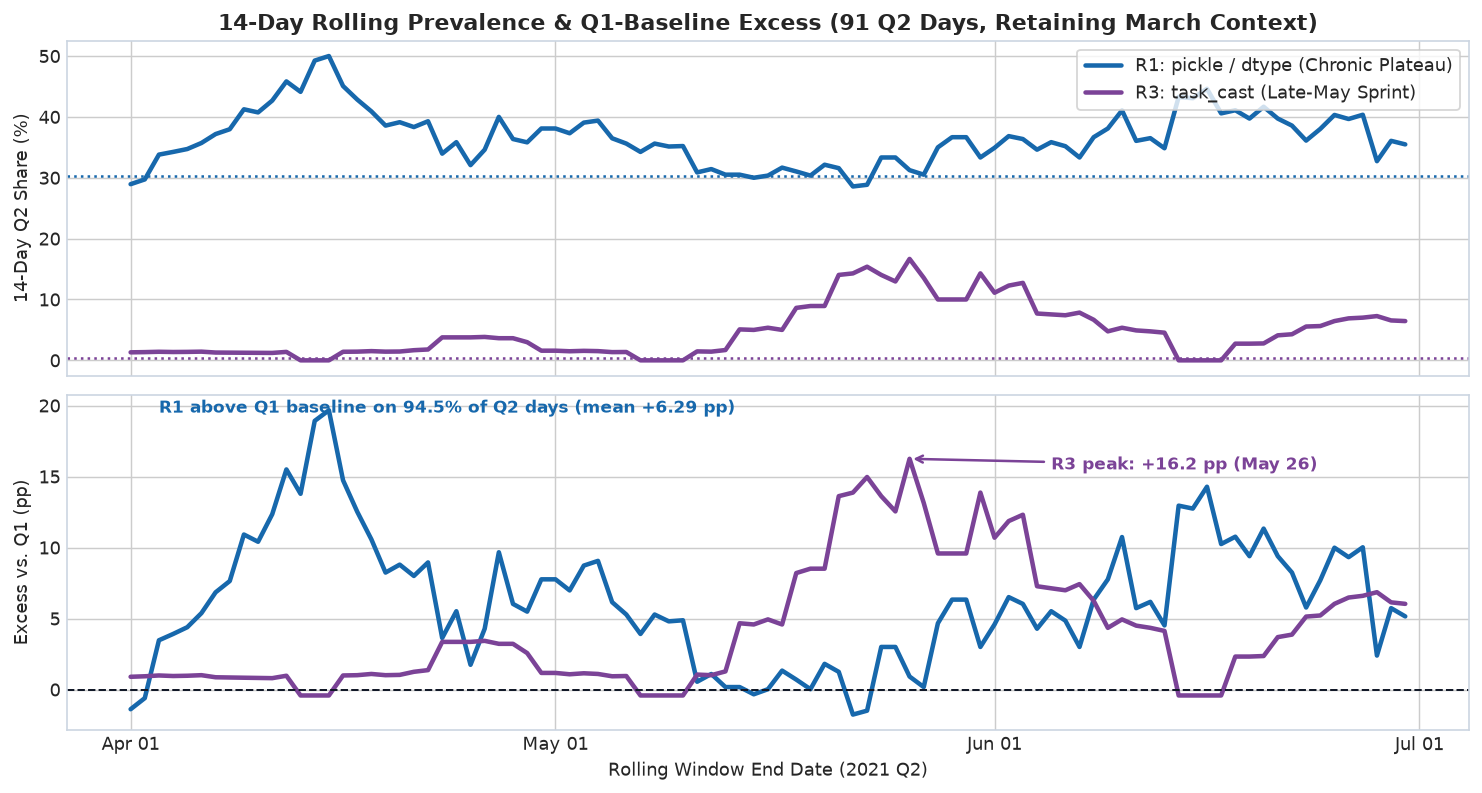

In [4]:
# 3A. Quarterly Fisher + BH FDR Shift Table (Exp 2) & Live 14-Day Rolling Trajectory Comparison
shifts_table = pd.read_csv(ROOT / "final_experiments" / "exp2_quarterly_shifts_with_stats.csv")
mk_table = pd.read_csv(ROOT / "final_experiments" / "exp2_q2_trajectories_mann_kendall.csv")

print("Top Significant Bounded EOM Quarterly Shifts (BH FDR q < 0.10):")
display(shifts_table[shifts_table["FDR_Significant_010"]][
    ["Cluster_ID", "Technical_Subsystem", "Count_Q1", "Count_Q2", "P_Q1", "P_Q2", "Delta_K", "Q_Value_BH_FDR", "Category"]
].round(4))

# Run reusable temporal_tracking & trajectory_comparisons on saved R0..R9 assignments
assignments = pd.read_csv(ROOT / "paper_q2_results" / "topic_assignments.csv")
with open(ROOT / "paper_q2_results" / "topic_labels.json") as f:
    labels_json = json.load(f)

analysis = analyze_temporal_topics(
    assignments, topic_labels=labels_json,
    config=TemporalConfig(window_days=14, step_days=1, min_window_tickets=5),
)
q2_focus = focus_topic_quarter(analysis, quarter="2021Q2")
comp = compare_quarter_trajectories(analysis, baseline_quarter="2021Q1", target_quarter="2021Q2")
excess_df = comp["baseline_excess"]

fig, (top, bot) = plt.subplots(2, 1, figsize=(11.5, 6.2), sharex=True)
for cid, name, col in [(1, "R1: pickle / dtype (Chronic Plateau)", "#1768ac"), (3, "R3: task_cast (Late-May Sprint)", "#7b4397")]:
    sub = excess_df[excess_df["Cluster_ID"] == cid].sort_values("Window_End")
    top.plot(sub["Window_End"], sub["Target_Prevalence"] * 100, color=col, lw=2.5, label=name)
    top.axhline(sub["Baseline_Prevalence"].iloc[0] * 100, color=col, lw=1.4, ls=":")
    bot.plot(sub["Window_End"], sub["Excess_PP"], color=col, lw=2.5, label=name)

r1_above = (excess_df[excess_df["Cluster_ID"] == 1]["Excess_PP"] > 0).mean() * 100
r3_sub = excess_df[excess_df["Cluster_ID"] == 3]
r3_peak = r3_sub.loc[r3_sub["Excess_PP"].idxmax()]

top.set_ylabel("14-Day Q2 Share (%)")
top.set_title("14-Day Rolling Prevalence & Q1-Baseline Excess (91 Q2 Days, Retaining March Context)", fontweight="bold")
top.legend(loc="upper right", frameon=True)
bot.axhline(0, color="#111827", lw=1.1, ls="--")
bot.set_ylabel("Excess vs. Q1 (pp)")
bot.set_xlabel("Rolling Window End Date (2021 Q2)")
bot.text(pd.Timestamp("2021-04-03"), 19.5, f"R1 above Q1 baseline on {r1_above:.1f}% of Q2 days (mean +6.29 pp)",
         color="#1768ac", fontweight="bold", fontsize=9.5)
bot.annotate(f"R3 peak: +{r3_peak['Excess_PP']:.1f} pp ({r3_peak['Window_End']:%b %d})",
             xy=(r3_peak["Window_End"], r3_peak["Excess_PP"]),
             xytext=(pd.Timestamp("2021-06-05"), 15.5),
             color="#7b4397", fontweight="bold", fontsize=9.5,
             arrowprops={"arrowstyle": "->", "color": "#7b4397", "lw": 1.4})
bot.xaxis.set_major_locator(mdates.MonthLocator())
bot.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()


---
## 4. Trap 2B: Exposing Pooling Cancellation in Enterprise IT (`it_incident_tickets.csv`)

When January baseline traffic ($N=487$) is compared against **pooled February + March** ($N=851$), **0 out of 14** IT clusters survive FDR control ($q \ge 0.23$). Why? In Software Installations (`IT-03`), a February lull (`-4.43 pp`, down to `11.59%`) and a March surge (`+9.88 pp`, up to `21.47%`) cancel `99%` of their variation when pooled (`Coarse Δ = -0.15 pp, q = 1.0`). Sequential monthly testing (March vs. Jan+Feb) exposes **4 statistically significant shifts** that agree in sign with 14-day $\tau_{\text{MK}}$.


Coarse Feb+Mar vs Jan FDR-significant clusters : 0 / 14
Monthly Mar vs Jan+Feb FDR-significant clusters: 4 / 14


,Cluster_ID,Dominant_Subcategory,P_Jan_Pct,P_Feb_Pct,P_Mar_Pct,Coarse_Delta_FebMar_vs_Jan_PP,Monthly_Delta_Mar_vs_JanFeb_PP,Monthly_Q_BH_FDR,Rolling_Kendall_Tau
0,IT-03,INSTALLATION,16.02,11.59,21.47,-0.15,7.65,0.0074,0.1666
2,IT-02,CONFIGURATION,0.82,0.62,3.53,1.06,2.81,0.0065,0.4552
10,IT-08,ERROR,2.87,3.52,0.54,-0.64,-2.65,0.0132,-0.2532
13,IT-10,ERROR,12.11,11.59,7.34,-2.36,-4.52,0.0591,-0.2655


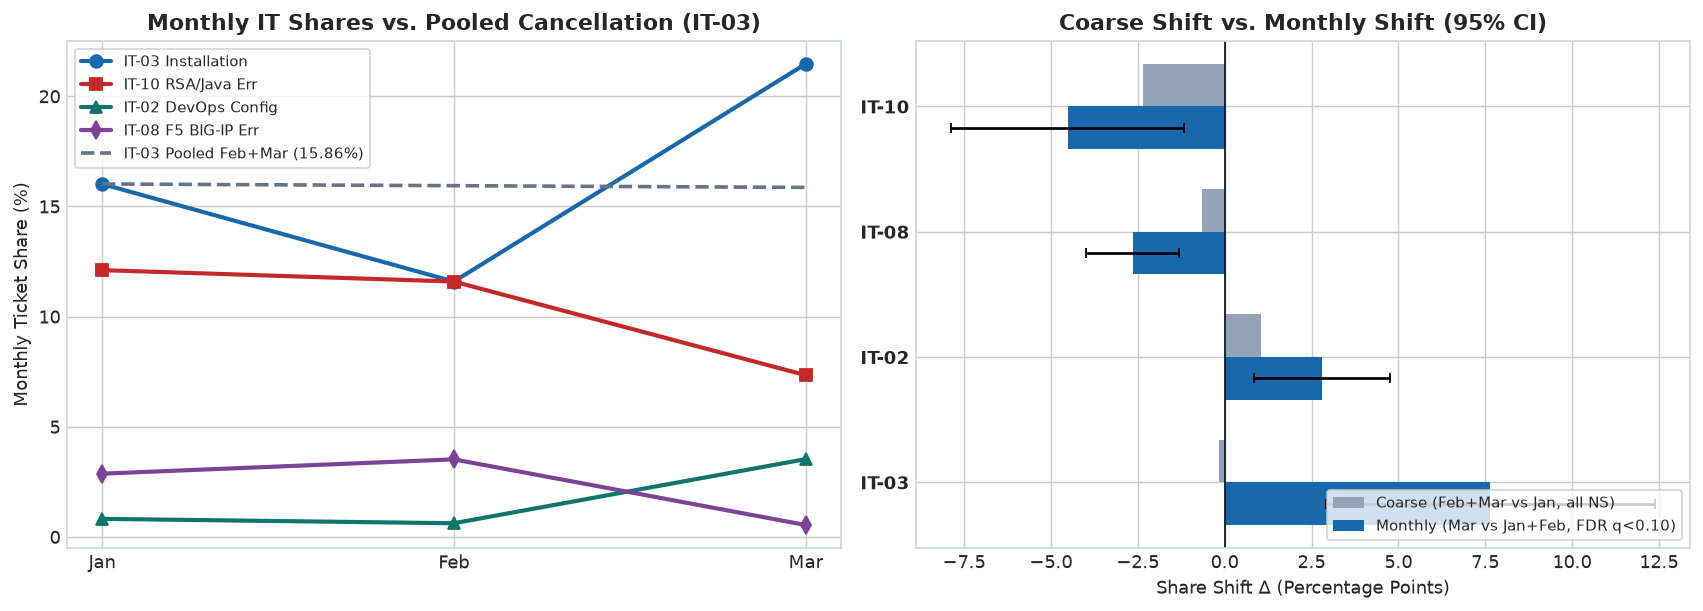

In [5]:
# 4. Reproduce Pooling Cancellation Table & Figure on Enterprise IT (Exp 8)
exp8 = pd.read_csv(ROOT / "final_experiments" / "exp8_it_coarse_vs_monthly_shifts.csv")
print(f"Coarse Feb+Mar vs Jan FDR-significant clusters : {int(exp8['Coarse_FDR_Sig_010'].sum())} / {len(exp8)}")
print(f"Monthly Mar vs Jan+Feb FDR-significant clusters: {int(exp8['Monthly_FDR_Sig_010'].sum())} / {len(exp8)}")

display(exp8.loc[exp8["Monthly_FDR_Sig_010"], [
    "Cluster_ID", "Dominant_Subcategory", "P_Jan_Pct", "P_Feb_Pct", "P_Mar_Pct",
    "Coarse_Delta_FebMar_vs_Jan_PP", "Monthly_Delta_Mar_vs_JanFeb_PP", "Monthly_Q_BH_FDR", "Rolling_Kendall_Tau"
]].round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8))

# Panel A: Monthly Trajectory of Key IT Clusters + Pooled Ghost Line for IT-03
focus_it = [
    ("IT-03", "IT-03 Installation", "#1768ac", "-o"),
    ("IT-10", "IT-10 RSA/Java Err", "#c62828", "-s"),
    ("IT-02", "IT-02 DevOps Config", "#0f766e", "-^"),
    ("IT-08", "IT-08 F5 BIG-IP Err", "#7b4397", "-d"),
]
months = ["Jan", "Feb", "Mar"]
for cid, label, col, fmt in focus_it:
    row = exp8[exp8["Cluster_ID"] == cid].iloc[0]
    ax1.plot(months, [row["P_Jan_Pct"], row["P_Feb_Pct"], row["P_Mar_Pct"]], fmt, color=col, lw=2.3, ms=7, label=label)

it03 = exp8[exp8["Cluster_ID"] == "IT-03"].iloc[0]
pooled_feb_mar = (it03["Count_Feb"] + it03["Count_Mar"]) / (483 + 368) * 100
ax1.plot(["Jan", "Mar"], [it03["P_Jan_Pct"], pooled_feb_mar], "--", color="#64748b", lw=2.0, label=f"IT-03 Pooled Feb+Mar ({pooled_feb_mar:.2f}%)")
ax1.set_ylabel("Monthly Ticket Share (%)")
ax1.set_title("Monthly IT Shares vs. Pooled Cancellation (IT-03)", fontweight="bold")
ax1.legend(frameon=True, fontsize=8.5, loc="upper left")

# Panel B: Coarse Delta vs Monthly March Delta (95% CI)
bar_clusters = ["IT-03", "IT-02", "IT-08", "IT-10"]
sub8 = exp8.set_index("Cluster_ID").loc[bar_clusters].reset_index()
y = np.arange(len(sub8))
h = 0.34
ax2.barh(y + h/2, sub8["Coarse_Delta_FebMar_vs_Jan_PP"], height=h, color="#94a3b8", label="Coarse (Feb+Mar vs Jan, all NS)")
err_low = sub8["Monthly_Delta_Mar_vs_JanFeb_PP"] - sub8["Monthly_CI95_Low_PP"]
err_high = sub8["Monthly_CI95_High_PP"] - sub8["Monthly_Delta_Mar_vs_JanFeb_PP"]
ax2.barh(y - h/2, sub8["Monthly_Delta_Mar_vs_JanFeb_PP"], height=h, xerr=[err_low, err_high],
         color="#1768ac", capsize=3, label="Monthly (Mar vs Jan+Feb, FDR q<0.10)")
ax2.axvline(0, color="#111827", lw=1.0)
ax2.set_yticks(y)
ax2.set_yticklabels(sub8["Cluster_ID"], fontweight="bold")
ax2.set_xlabel("Share Shift Δ (Percentage Points)")
ax2.set_title("Coarse Shift vs. Monthly Shift (95% CI)", fontweight="bold")
ax2.legend(frameon=True, fontsize=8.5, loc="lower right")

plt.tight_layout()
plt.show()


---
## 5. Stage 3 Operational Payoff: Withheld Contributor Roles & Orphaned Incident Triage

All operational metadata ($m_i$) was withheld during discovery and tracking. Evaluating clusters against $m_i$ post hoc confirms both practical payoffs:
1. **GitHub SWE (`R0–R9`):** Cluster `R3` (`task_cast`) has **0.0% external community users** (`75% MEMBER, 25% CONTRIBUTOR`), exposing its May spike as an internal maintainer refactoring sprint, whereas `R0`, `R1`, and `R6` draw **33%–54%** external community bug reporters.
2. **Enterprise IT (`IT-00–IT-13`):** Five critical cross-boundary outage families (`IT-07`, `IT-08`, `IT-10`, `IT-12`, `IT-13`, `93.8%–100%` subcategory purity) capture Tier 1 intake blind spots and group **237 of 314 (75.5%)** orphaned `Unassigned` tickets with previously handled incidents, leaving 77 ambiguous tickets in noise `-1` for human review.


GitHub R3 external author share: 0.0 %
Orphaned Unassigned IT Tickets Grouped: 237 / 314 (75.5%) | Residual Noise: 77


,Cluster,N,External_User_Pct,Issue_Pct,PR_Pct,Median_MTTR_Hours,Topic_Label
0,R0,29,41.4,58.6,41.4,32.2,wikimedia / duplicatedkeyserror / timit_asr / duplicate
1,R1,298,32.9,52.0,48.0,65.2,pickle / dtype / pickle py / python3 pickle
2,R2,20,15.0,20.0,80.0,80.4,rename_column / formatted / foo / add_item
3,R3,20,0.0,30.0,70.0,122.5,git src / prepare_for_task / textclassification / datasetinfo
4,R4,29,34.5,51.7,48.3,45.2,char_error_rate / refs / cer / preds
5,R5,31,3.2,6.5,93.5,18.5,minor / readthedocs / readinstruction / bertscore
6,R6,83,54.2,68.7,31.3,38.2,numpy / core src / macosx / numpy core
7,R7,56,26.8,35.7,64.3,61.3,coco / rico / cards / add_new_dataset md
8,R8,44,11.4,34.1,65.9,68.8,speech / audio / hindi / openslr
9,R9,31,22.6,35.5,64.5,150.8,pdf / babi / entities / duorc


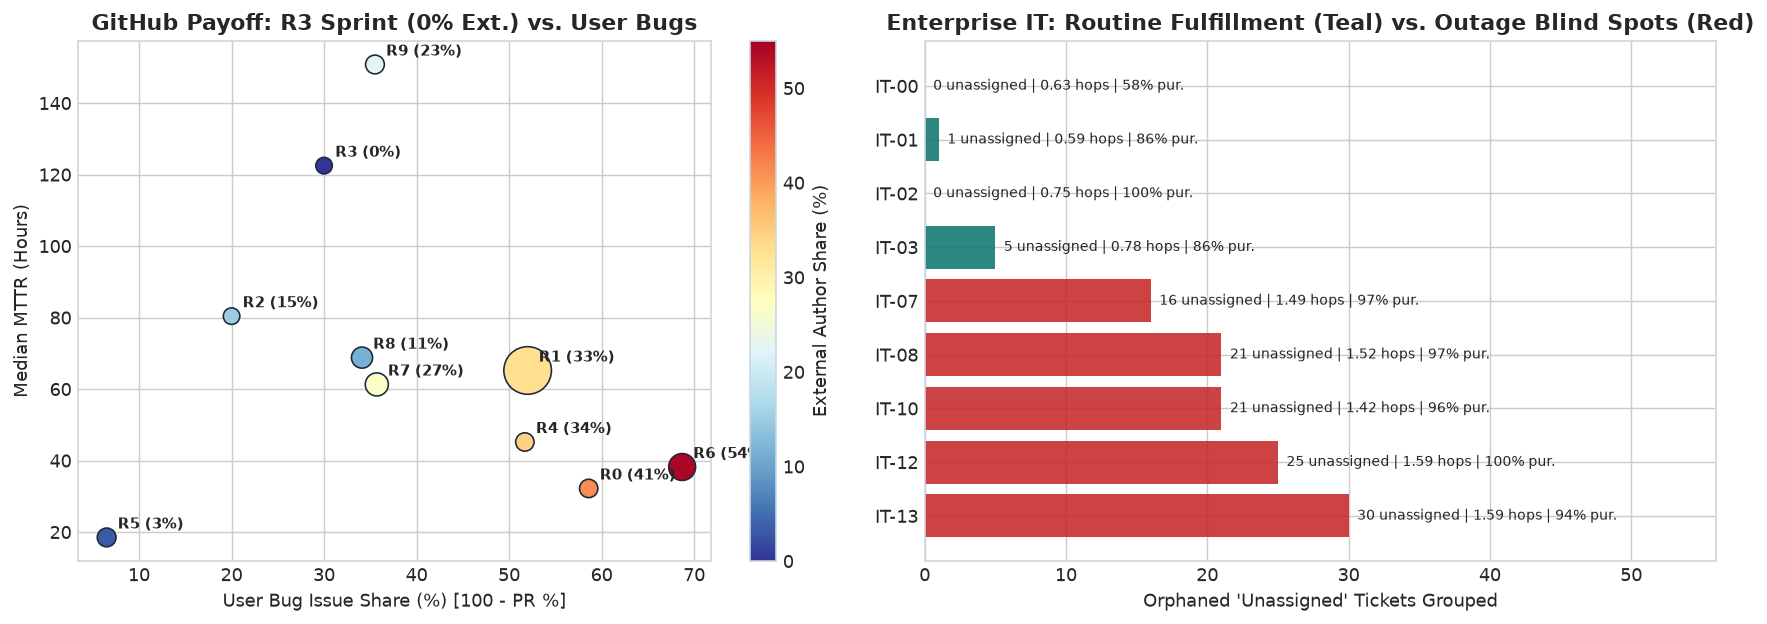

In [6]:
# 5. Direct Verification Against Withheld GitHub Roles & IT Queue Logs
df_gh["r_cluster"] = assignments["hdbscan_cluster"].to_numpy()
gh_role_rows = []
for r in sorted(c for c in df_gh["r_cluster"].unique() if c != -1):
    sub = df_gh[df_gh["r_cluster"] == r]
    ext_pct = (sub["author_association"] == "NONE").mean() * 100
    pr_pct = sub["is_pull_request"].mean() * 100
    issue_pct = 100.0 - pr_pct
    gh_role_rows.append({
        "Cluster": f"R{r}",
        "N": len(sub),
        "External_User_Pct": round(ext_pct, 1),
        "PR_Pct": round(pr_pct, 1),
        "Issue_Pct": round(issue_pct, 1),
    })
gh_roles = pd.DataFrame(gh_role_rows)
exp6_r10 = pd.read_csv(ROOT / "final_experiments" / "exp6_extrinsic_validation_r10.csv")
gh_merged = gh_roles.merge(exp6_r10[["Cluster_ID", "Median_MTTR_Hours", "Topic_Label"]], left_on="Cluster", right_on="Cluster_ID")
print("GitHub R3 external author share:", gh_merged.loc[gh_merged["Cluster"] == "R3", "External_User_Pct"].iloc[0], "%")
display(gh_merged[["Cluster", "N", "External_User_Pct", "Issue_Pct", "PR_Pct", "Median_MTTR_Hours", "Topic_Label"]])

exp9 = pd.read_csv(ROOT / "final_experiments" / "exp9_it_extrinsic_triage_and_routing.csv")
assigned_unassigned = int(exp9.loc[exp9["Cluster_ID"] != "Noise (-1)", "Unassigned_Tickets_Routed"].sum())
noise_unassigned = int(exp9.loc[exp9["Cluster_ID"] == "Noise (-1)", "Unassigned_Tickets_Routed"].iloc[0])
total_unassigned = assigned_unassigned + noise_unassigned
print(f"Orphaned Unassigned IT Tickets Grouped: {assigned_unassigned} / {total_unassigned} ({assigned_unassigned/total_unassigned*100:.1f}%) | Residual Noise: {noise_unassigned}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9))

# Panel A: GitHub Contributor Roles vs Median MTTR
sc = ax1.scatter(gh_merged["Issue_Pct"], gh_merged["Median_MTTR_Hours"],
                 s=gh_merged["N"] * 2.2 + 40, c=gh_merged["External_User_Pct"],
                 cmap="RdYlBu_r", vmin=0, vmax=55, edgecolors="#1e293b", lw=0.9)
plt.colorbar(sc, ax=ax1, label="External Author Share (%)")
for _, row in gh_merged.iterrows():
    ax1.text(row["Issue_Pct"] + 1.2, row["Median_MTTR_Hours"] + 2.5,
             f"{row['Cluster']} ({row['External_User_Pct']:.0f}%)", fontsize=8.3, fontweight="bold")
ax1.set_xlabel("User Bug Issue Share (%) [100 - PR %]")
ax1.set_ylabel("Median MTTR (Hours)")
ax1.set_title("GitHub Payoff: R3 Sprint (0% Ext.) vs. User Bugs", fontweight="bold")

# Panel B: Enterprise IT Orphaned Tickets & Reassignments
it_plot = exp9[exp9["Cluster_ID"].isin(["IT-00", "IT-01", "IT-02", "IT-03", "IT-10", "IT-07", "IT-08", "IT-12", "IT-13"])].copy()
colors_it = ["#0f766e" if c in ["IT-00", "IT-01", "IT-02", "IT-03"] else "#c62828" for c in it_plot["Cluster_ID"]]
bars = ax2.barh(it_plot["Cluster_ID"], it_plot["Unassigned_Tickets_Routed"], color=colors_it, alpha=0.88)
ax2.invert_yaxis()
for b, (_, row) in zip(bars, it_plot.iterrows()):
    ax2.text(b.get_width() + 0.6, b.get_y() + b.get_height()/2,
             f"{int(row['Unassigned_Tickets_Routed'])} unassigned | {row['Mean_Reassigned_Count']:.2f} hops | {row['Subcategory_Purity_Pct']:.0f}% pur.",
             va="center", fontsize=8)
ax2.set_xlim(0, 56)
ax2.set_xlabel("Orphaned 'Unassigned' Tickets Grouped")
ax2.set_title("Enterprise IT: Routine Fulfillment (Teal) vs. Outage Blind Spots (Red)", fontweight="bold")

plt.tight_layout()
plt.show()


---
## 6. Sensitivity Ablations, Prospective Generalization & Unit Tests

- **Prospective Generalization (`exp4` & `exp10`):** Fitting strictly on Q1 and projecting Q2/March forward achieves strong rank agreement with retrospective shifts (Spearman $\rho = 0.891, p=5.4\times 10^{-4}$ on GitHub; $\rho = 0.960, p=5.1\times 10^{-8}$ on Enterprise IT) and `100%` recall on the 2024 long-horizon IT slice.
- **Software Verification:** All temporal tracking, UTC calendar boundary, noise denominator, and trajectory comparison invariants are tested by 90 unit tests under `tests/`.


In [7]:
# 6. Summary of Ablations, Prospective Evaluation & Live Unit Test Run
exp3a = pd.read_csv(ROOT / "final_experiments" / "exp3a_umap_dimension_ablation.csv")
exp4 = json.loads((ROOT / "final_experiments" / "exp4_prospective_summary.json").read_text())
exp10 = json.loads((ROOT / "final_experiments" / "exp10_cross_domain_regime_summary.json").read_text())

print("UMAP Dimensionality Ablation (Bounded EOM vs EOM):")
display(exp3a[exp3a["Dimensions_d"].isin([2, 3, 5, 10, 25, 384])][
    ["Dimensions_d", "Method", "Clusters_K", "Noise_Ratio", "Max_Cluster_Share_Clean", "Sil_Manifold"]
].round(4))

print("Cross-Domain Prospective Summary:")
print(f"  GitHub SWE   -> Spearman rho = {exp4['delta_k_spearman_rho']:.4f} (p = {exp4['delta_k_spearman_p']:.2e}), Hybrid ARI = {exp4['hybrid_prospective_ari']:.4f}")
print(f"  Enterprise IT -> Spearman rho = {exp10['regime_1_enterprise_it']['prospective_delta_spearman_rho']:.4f} (p = {exp10['regime_1_enterprise_it']['prospective_delta_spearman_p']:.2e}), Hybrid ARI = {exp10['regime_1_enterprise_it']['prospective_hybrid_mar_ari']:.4f}")

import unittest
suite = unittest.defaultTestLoader.discover("tests")
runner = unittest.TextTestRunner(verbosity=0)
res = runner.run(suite)
print(f"Unit Tests: {res.testsRun} run, {len(res.failures)} failures, {len(res.errors)} errors -> {'PASS' if res.wasSuccessful() else 'FAIL'}")


UMAP Dimensionality Ablation (Bounded EOM vs EOM):
Cross-Domain Prospective Summary:
  GitHub SWE   -> Spearman rho = 0.8909 (p = 5.42e-04), Hybrid ARI = 0.6623
  Enterprise IT -> Spearman rho = 0.9604 (p = 5.08e-08), Hybrid ARI = 0.9831
Unit Tests: 90 run, 0 failures, 0 errors -> PASS


----------------------------------------------------------------------
Ran 90 tests in 4.615s

OK


,Dimensions_d,Method,Clusters_K,Noise_Ratio,Max_Cluster_Share_Clean,Sil_Manifold
0,2,EOM,18,0.2747,0.1894,0.4343
1,2,Bounded-EOM (max=120),20,0.3121,0.1040,0.5289
2,3,EOM,16,0.3190,0.1567,0.4935
3,3,Bounded-EOM (max=120),16,0.3190,0.1567,0.4935
4,5,EOM,10,0.2724,0.4649,0.3780
5,5,Bounded-EOM (max=120),14,0.3814,0.1688,0.5312
6,10,EOM,14,0.2667,0.2910,0.3925
7,10,Bounded-EOM (max=120),16,0.3519,0.1821,0.5121
10,25,EOM,17,0.2951,0.2222,0.5277
11,25,Bounded-EOM (max=120),16,0.4518,0.1035,0.5732
